## 1. Imports and helper functions

Create output directories and define the shared figure and linear-fit helpers.


In [18]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np

# Install requirements.txt in the selected Python environment before running.
Path("figure").mkdir(exist_ok=True)

RESULT_DIR = Path("results")
RESULT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11})

def save_figure(figure, filename):
    """Save the specific figure before displaying it in the notebook."""
    figure.tight_layout()
    figure.savefig(Path("figure") / filename, dpi=300, bbox_inches="tight")

def linear_summary(x, y):
    """Return a descriptive linear fit, Pearson r and in-sample R-squared."""
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]
    if len(x) < 3 or np.ptp(x) == 0 or np.ptp(y) == 0:
        raise ValueError("The linear summary needs at least three non-constant valid pairs.")
    slope, intercept = np.polyfit(x, y, 1)
    predicted = slope * x + intercept
    r = np.corrcoef(x, y)[0, 1]
    r_squared = 1 - np.sum((y - predicted) ** 2) / np.sum((y - y.mean()) ** 2)
    return slope, intercept, r, r_squared


## 2. Read, clean and combine data

Use the supplied local snapshots. Validate dates, numeric counts and monthly joins.


In [19]:
covid = pd.read_csv("data/daily-new-confirmed-covid-19-cases-per-million-people.csv")
covid["Day"] = pd.to_datetime(covid["Day"])
dutch_cases = covid.loc[covid["Entity"] == "Netherlands"].copy().sort_values("Day")
dutch_cases["Datum"] = (dutch_cases["Day"].dt.to_period("M").dt.to_timestamp())
monthly_cases = (dutch_cases.groupby("Datum", as_index=False)["New cases (per 1M)"].mean().rename(columns={"New cases (per 1M)": "Covid_per_miljoen"}))

raw_passengers = pd.read_excel(
    "data/Monthly_traffic_data_1992-current-2.xlsx",
    sheet_name="Standard&Poors",
    header=8
)

passengers = raw_passengers.iloc[:, [0, 1, 6, 7, 8, 10, 11]].copy()
passengers.columns = [
    "Jaar",
    "Maand",
    "Europa",
    "Intercontinentaal",
    "Totaal",
    "OD",
    "Transfer"
]

passengers["Jaar"] = pd.to_numeric(passengers["Jaar"], errors="coerce").ffill()

month_numbers = {
    "January": 1,
    "February": 2,
    "March": 3,
    "April": 4,
    "May": 5,
    "June": 6,
    "July": 7,
    "August": 8,
    "September": 9,
    "October": 10,
    "November": 11,
    "December": 12
}

passengers = passengers.loc[passengers["Maand"].isin(month_numbers)].copy()
passengers["Jaar"] = passengers["Jaar"].astype(int)
passengers["Maandnummer"] = passengers["Maand"].map(month_numbers)

passengers["Datum"] = pd.to_datetime({
    "year": passengers["Jaar"],
    "month": passengers["Maandnummer"],
    "day": 1
})

categories = ["Europa", "Intercontinentaal", "Totaal", "OD", "Transfer"]

for category in categories:
    passengers[category] = pd.to_numeric(
        passengers[category], errors="raise"
    )

passengers = passengers.sort_values("Datum")

if passengers["Datum"].duplicated().any():
    raise ValueError("Er staan dubbele maanden in de Schiphol-data.")

reference_2019 = passengers.loc[
    passengers["Jaar"] == 2019
].set_index("Maandnummer")

if len(reference_2019) != 12:
    raise ValueError("Voor 2019 zijn niet alle twaalf maanden beschikbaar.")

for category in categories:
    baseline = passengers["Maandnummer"].map(reference_2019[category])
    passengers[f"{category}_index"] = passengers[category] / baseline * 100

pandemic = passengers.loc[
    passengers["Jaar"].between(2020, 2022)
].merge(
    monthly_cases,
    on="Datum",
    how="left",
    validate="one_to_one"
)

if pandemic["Covid_per_miljoen"].isna().any():
    raise ValueError("Missing monthly COVID-19 observations after merging.")
if len(pandemic) != 36:
    raise ValueError("Expected 36 monthly observations for 2020–2022.")
print("Data ready: 36 pandemic months, no missing merged monthly case values.")
expected_months = pd.date_range("1992-01-01", "2026-08-01", freq="MS")
observed_months = pd.DatetimeIndex(passengers["Datum"])
if not observed_months.equals(expected_months):
    raise ValueError("The supplied passenger snapshot must contain every month from January 1992 to August 2026.")
if not np.isfinite(passengers[categories].to_numpy(dtype=float)).all():
    raise ValueError("Passenger counts contain missing or non-finite values.")
print("Passenger coverage verified: 416 consecutive months, with valid counts in all five columns.")


Data ready: 36 pandemic months, no missing merged monthly case values.
Passenger coverage verified: 416 consecutive months, with valid counts in all five columns.


## 3. RQ1: Long-term passenger development

Aggregate the monthly series to annual totals before 2020.


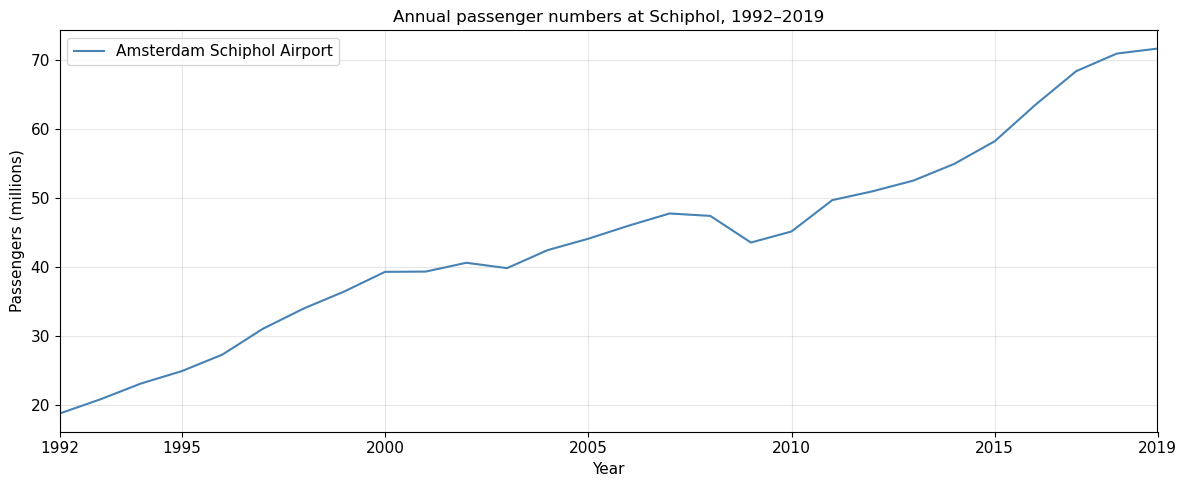

In [20]:
before_pandemic = passengers.loc[
    passengers["Jaar"].between(1992, 2019)
]

annual_totals = (
    before_pandemic.groupby("Jaar", as_index=False)["Totaal"].sum()
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    annual_totals["Jaar"],
    annual_totals["Totaal"] / 1_000_000,
    label="Amsterdam Schiphol Airport",
    color="steelblue",
    linewidth=1.5
)

ax.set_title("Annual passenger numbers at Schiphol, 1992–2019")
ax.set_xlabel("Year")
ax.set_ylabel("Passengers (millions)")
ax.legend()
ax.grid(alpha=0.3)

ax.set_xlim(1992, 2019)
ax.set_xticks([1992, 1995, 2000, 2005, 2010, 2015, 2019])
fig.tight_layout()
save_figure(fig, "schiphol_annual_passengers.png")
plt.show()

## 4. RQ1: Average and period-level seasonality

Calculate within-year indices and compare average monthly patterns.


Historical data check passed.


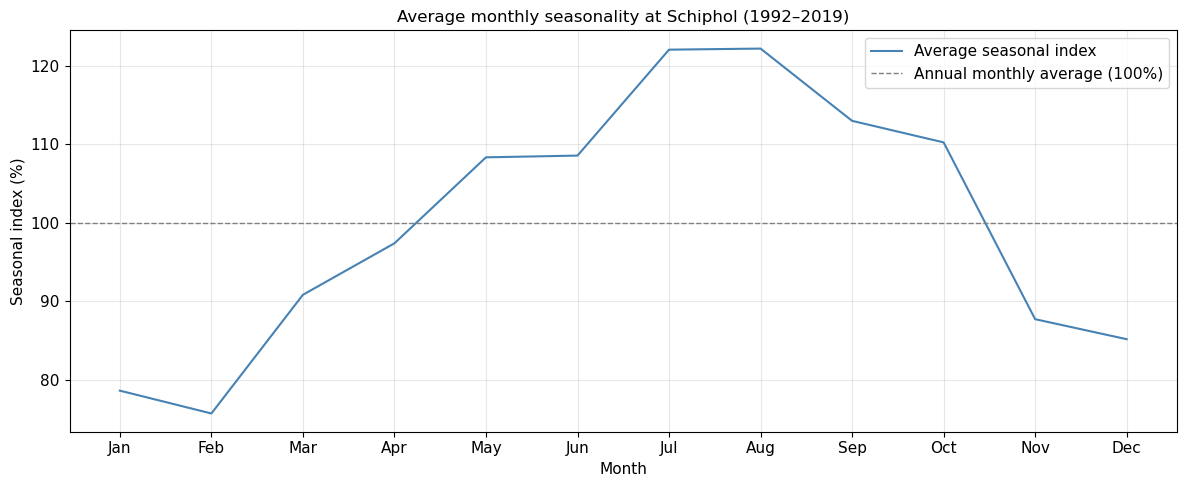

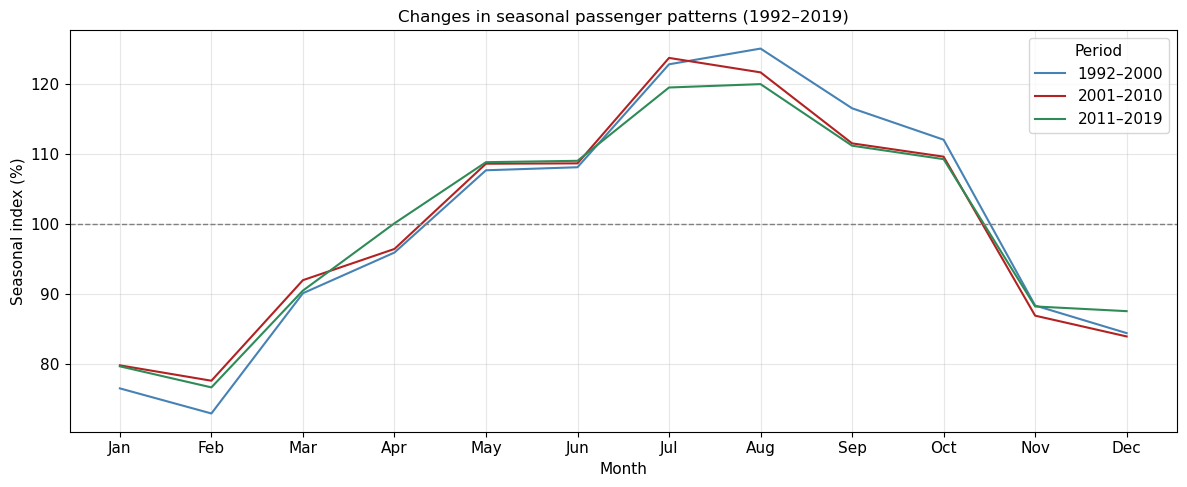


HISTORICAL SEASONALITY SUMMARY
   Period Peak_month  Peak_index Lowest_month  Lowest_index  Mean_absolute_deviation
1992–2000        Aug      125.04          Feb         72.87                    15.35
2001–2010        Jul      123.71          Feb         77.55                    13.94
2011–2019        Aug      119.96          Feb         76.60                    12.95

Historical seasonality analysis completed.


In [21]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

Path("figure").mkdir(exist_ok=True)


# Select data

hist_data = passengers.loc[
    passengers["Jaar"].between(1992, 2019),
    ["Jaar", "Maandnummer", "Totaal"]
].copy()

hist_data["Totaal"] = pd.to_numeric(
    hist_data["Totaal"],
    errors="coerce"
)

hist_data = hist_data.sort_values(
    ["Jaar", "Maandnummer"]
)



if hist_data.duplicated(
    ["Jaar", "Maandnummer"]
).any():
    raise ValueError("Duplicate year-month observations found.")

hist_check = hist_data.groupby("Jaar").agg(
    Months=("Maandnummer", "nunique"),
    Missing=("Totaal", lambda x: x.isna().sum())
)

if (
    len(hist_check) != 28
    or (hist_check["Months"] != 12).any()
    or (hist_check["Missing"] > 0).any()
):
    raise ValueError("Incomplete historical data.")

print("Historical data check passed.")

# Calculate within-year seasonal indices

hist_data["Yearly_monthly_avg"] = (
    hist_data.groupby("Jaar")["Totaal"]
    .transform("mean")
)

hist_data["Seasonal_index"] = (
    hist_data["Totaal"]
    / hist_data["Yearly_monthly_avg"]
    * 100
)

hist_months = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]


# Average the indices for each calendar month

hist_average = (
    hist_data.groupby("Maandnummer")["Seasonal_index"]
    .mean()
    .reindex(range(1, 13))
)

fig_hist_avg, ax_hist_avg = plt.subplots(figsize=(12, 5))

ax_hist_avg.plot(
    hist_average.index,
    hist_average.values,
    color="steelblue",
    label="Average seasonal index",
    linewidth=1.5
)

ax_hist_avg.axhline(
    100,
    color="gray",
    linestyle="--",
    linewidth=1,
    label="Annual monthly average (100%)"
)

ax_hist_avg.set_title(
    "Average monthly seasonality at Schiphol (1992–2019)"
)

ax_hist_avg.set_xlabel("Month")
ax_hist_avg.set_ylabel("Seasonal index (%)")

ax_hist_avg.set_xticks(range(1, 13))
ax_hist_avg.set_xticklabels(hist_months)

ax_hist_avg.grid(alpha=0.3)
ax_hist_avg.legend()

fig_hist_avg.tight_layout()

save_figure(fig_hist_avg, "schiphol_monthly_seasonality.png")

plt.show()


# Compare the three historical periods

hist_data["Period"] = pd.cut(
    hist_data["Jaar"],
    bins=[1991, 2000, 2010, 2019],
    labels=[
        "1992–2000",
        "2001–2010",
        "2011–2019"
    ]
)

hist_periods = (
    hist_data.groupby(
        ["Maandnummer", "Period"],
        observed=True
    )["Seasonal_index"]
    .mean()
    .unstack("Period")
    .reindex(range(1, 13))
)

hist_colors = {
    "1992–2000": "steelblue",
    "2001–2010": "firebrick",
    "2011–2019": "seagreen"
}

fig_hist_period, ax_hist_period = plt.subplots(figsize=(12, 5))

for hist_period in hist_periods.columns:

    ax_hist_period.plot(
        hist_periods.index,
        hist_periods[hist_period],
        color=hist_colors[str(hist_period)],
        linewidth=1.5,
        label=str(hist_period)
    )

ax_hist_period.axhline(
    100,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax_hist_period.set_title(
    "Changes in seasonal passenger patterns (1992–2019)"
)

ax_hist_period.set_xlabel("Month")
ax_hist_period.set_ylabel("Seasonal index (%)")

ax_hist_period.set_xticks(range(1, 13))
ax_hist_period.set_xticklabels(hist_months)

ax_hist_period.grid(alpha=0.3)
ax_hist_period.legend(title="Period")

fig_hist_period.tight_layout()

save_figure(fig_hist_period, "schiphol_seasonality_comparison.png")

plt.show()


hist_strength = (
    hist_periods.sub(100)
    .abs()
    .mean(axis=0)
)

hist_summary_rows = []

for hist_period in hist_periods.columns:

    hist_indices = hist_periods[hist_period]

    hist_peak_month = int(hist_indices.idxmax())
    hist_low_month = int(hist_indices.idxmin())

    hist_summary_rows.append({
        "Period": str(hist_period),
        "Peak_month": hist_months[hist_peak_month - 1],
        "Peak_index": hist_indices.max(),
        "Lowest_month": hist_months[hist_low_month - 1],
        "Lowest_index": hist_indices.min(),
        "Mean_absolute_deviation": hist_strength[hist_period]
    })

hist_summary = pd.DataFrame(hist_summary_rows)

print("\nHISTORICAL SEASONALITY SUMMARY")
print(hist_summary.round(2).to_string(index=False))


hist_summary.to_csv(
    "results/schiphol_seasonality_summary.csv",
    index=False
)

print("\nHistorical seasonality analysis completed.")


## 5. RQ1: Seasonal strength in each year

Use the same seasonal indices, but summarise each year separately. The line is descriptive, with no significance test.


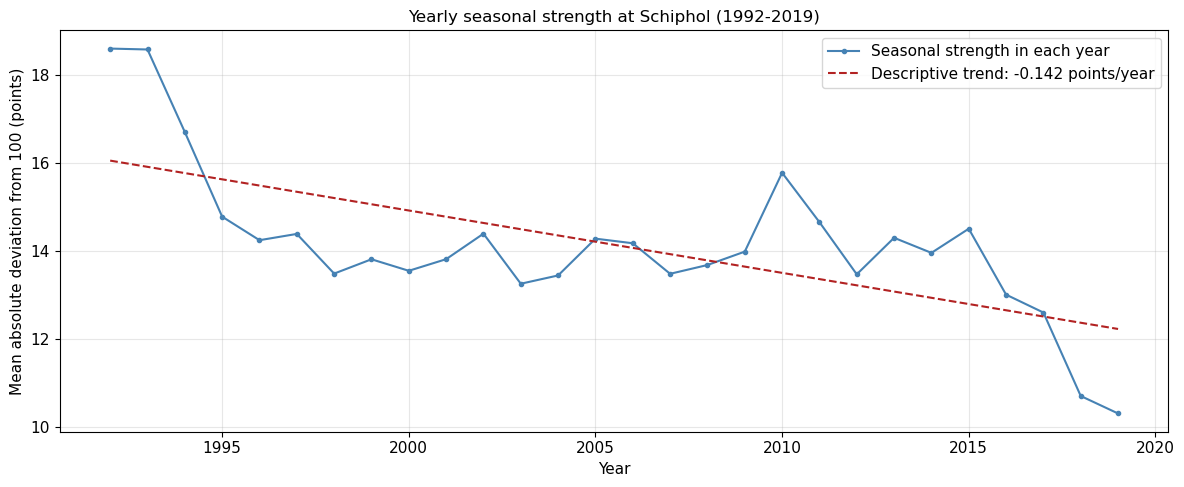

           count    mean     min     max
Period                                  
1992-2000      9  15.346  13.484  18.594
2001-2010     10  14.026  13.254  15.774
2011-2019      9  13.055  10.308  14.653
Yearly trend: -0.1416 points/year; r = -0.663; R-squared = 0.440


In [22]:
# Describe seasonal strength separately for each complete historical year.
annual_seasonality = hist_data.groupby("Jaar")["Seasonal_index"].apply(
    lambda values: (values - 100).abs().mean()
).rename("Mean_absolute_deviation").reset_index()
annual_seasonality["Period"] = pd.cut(
    annual_seasonality["Jaar"], bins=[1991, 2000, 2010, 2019],
    labels=["1992-2000", "2001-2010", "2011-2019"]
)
seasonality_by_period = annual_seasonality.groupby("Period", observed=True)[
    "Mean_absolute_deviation"
].agg(["count", "mean", "min", "max"])
x = annual_seasonality["Jaar"].to_numpy()
y = annual_seasonality["Mean_absolute_deviation"].to_numpy()
seasonal_slope, seasonal_intercept, seasonal_r, seasonal_r2 = linear_summary(x, y)
annual_seasonality["Linear_fit"] = seasonal_slope * x + seasonal_intercept
annual_seasonality.to_csv(RESULT_DIR / "annual_seasonal_strength.csv", index=False)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(x, y, color="steelblue", linewidth=1.5, marker="o", markersize=3,
        label="Seasonal strength in each year")
ax.plot(x, annual_seasonality["Linear_fit"], color="firebrick", linestyle="--",
        linewidth=1.5, label=f"Descriptive trend: {seasonal_slope:.3f} points/year")
ax.set(title="Yearly seasonal strength at Schiphol (1992-2019)", xlabel="Year",
       ylabel="Mean absolute deviation from 100 (points)")
ax.grid(alpha=0.3); ax.legend()
save_figure(fig, "schiphol_annual_seasonal_strength.png")
plt.show()
print(seasonality_by_period.round(3).to_string())
print(f"Yearly trend: {seasonal_slope:.4f} points/year; r = {seasonal_r:.3f}; R-squared = {seasonal_r2:.3f}")


## 6. RQ2: Passenger and case-report time series

Compare the timing of changes during 2020-2022.


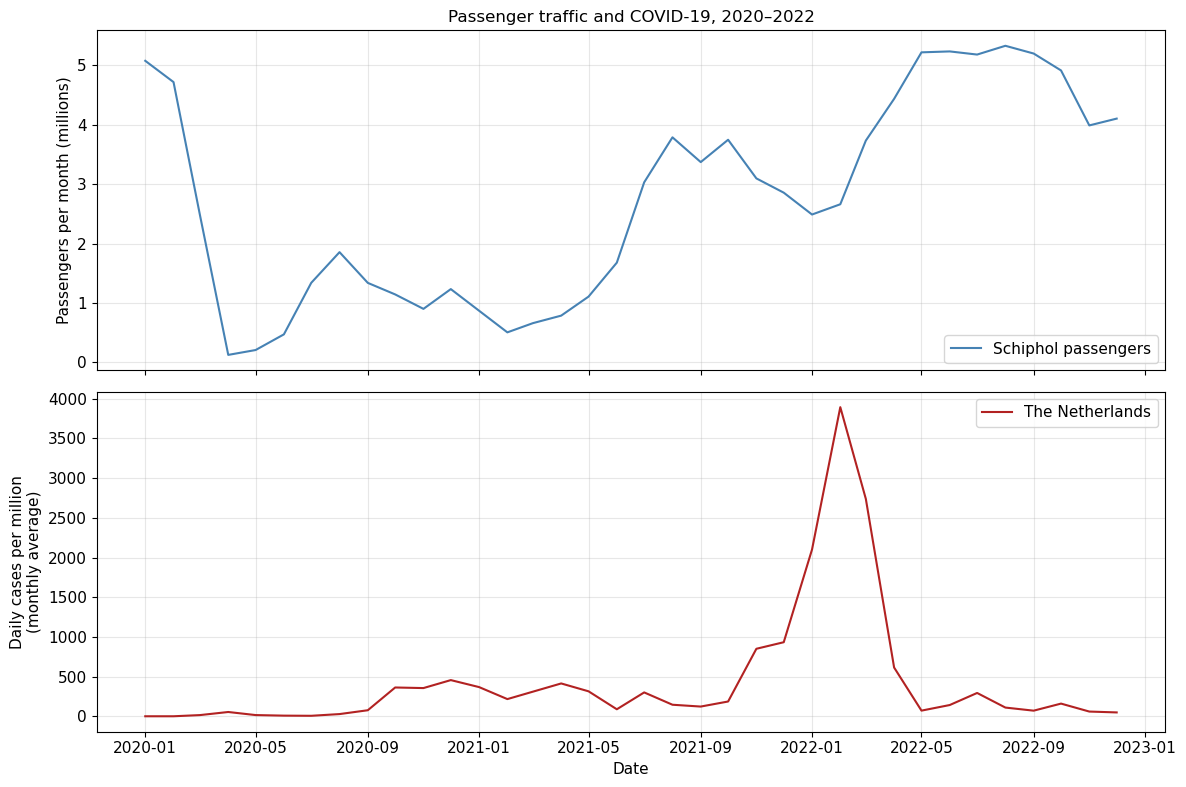

In [23]:
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True
)

ax1.plot(
    pandemic["Datum"],
    pandemic["Totaal"] / 1_000_000,
    label="Schiphol passengers",
    color="steelblue",
    linewidth=1.5
)

ax1.set_title("Passenger traffic and COVID-19, 2020–2022")
ax1.set_ylabel("Passengers per month (millions)")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(
    pandemic["Datum"],
    pandemic["Covid_per_miljoen"],
    label="The Netherlands",
    color="firebrick",
    linewidth=1.5
)

ax2.set_xlabel("Date")
ax2.set_ylabel("Daily cases per million\n(monthly average)")
ax2.legend()
ax2.grid(alpha=0.3)

fig.tight_layout()
Path("figure").mkdir(exist_ok=True)
save_figure(fig, "covid_netherlands_world.png")
plt.show()

## 7. RQ2: Pooled association

Describe the same-month relationship across all 36 observations.


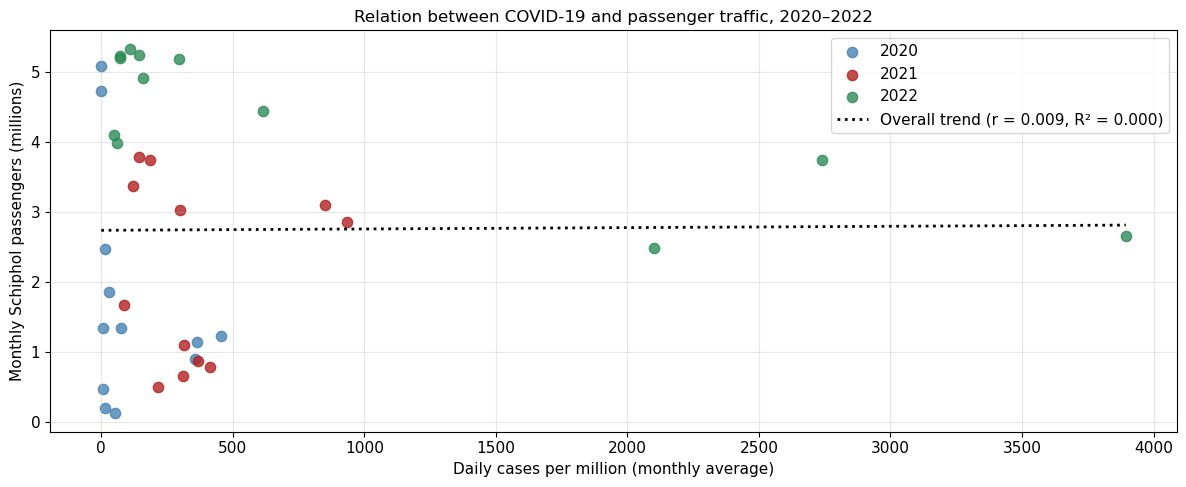

In [24]:
fig, ax = plt.subplots(figsize=(12, 5))

for year, colour in [
    (2020, "steelblue"),
    (2021, "firebrick"),
    (2022, "seagreen")
]:
    data = pandemic.loc[pandemic["Jaar"] == year]

    ax.scatter(
        data["Covid_per_miljoen"],
        data["Totaal"] / 1_000_000,
        label=str(year),
        color=colour,
        s=55,
        alpha=0.8
    )

pooled_data = pandemic.loc[
    pandemic["Jaar"].between(2020, 2022),
    ["Covid_per_miljoen", "Totaal"]
].dropna()

x = pooled_data["Covid_per_miljoen"].to_numpy()
y = pooled_data["Totaal"].to_numpy() / 1_000_000

slope, intercept, r, r2 = linear_summary(x, y)
x_line = np.linspace(x.min(), x.max(), 100)

ax.plot(
    x_line,
    slope * x_line + intercept,
    label=f"Overall trend (r = {r:.3f}, R² = {r2:.3f})",
    color="black",
    linestyle=":",
    linewidth=2
)

ax.set_title("Relation between COVID-19 and passenger traffic, 2020–2022")
ax.set_xlabel("Daily cases per million (monthly average)")
ax.set_ylabel("Monthly Schiphol passengers (millions)")
ax.legend()
ax.grid(alpha=0.3)

from pathlib import Path

Path("figure").mkdir(exist_ok=True)

fig.tight_layout()
save_figure(fig, "covid_passengers_total.png")
plt.show()

## 8. RQ2: Associations by year

Compare the yearly relationships on shared axes.


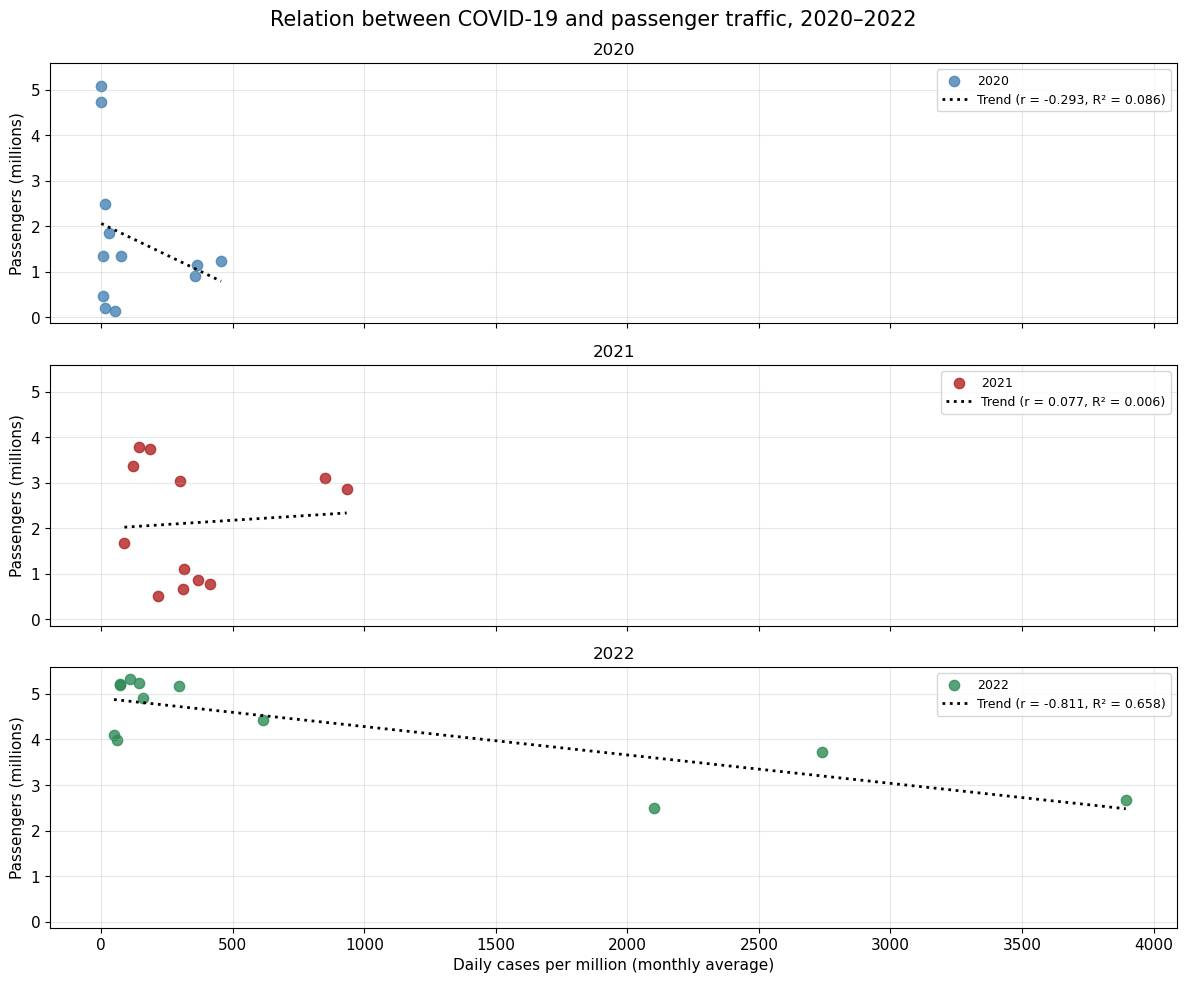

In [25]:
fig, axes = plt.subplots(
    3, 1, figsize=(12, 10), sharex=True, sharey=True
)

for ax, year, colour in zip(
    axes,
    [2020, 2021, 2022],
    ["steelblue", "firebrick", "seagreen"]
):
    data = pandemic.loc[
        pandemic["Jaar"] == year,
        ["Covid_per_miljoen", "Totaal"]
    ].dropna()

    x = data["Covid_per_miljoen"].to_numpy()
    y = data["Totaal"].to_numpy() / 1_000_000

    ax.scatter(
        x,
        y,
        label=str(year),
        color=colour,
        s=55,
        alpha=0.8
    )

    slope, intercept, r, r2 = linear_summary(x, y)
    x_line = np.linspace(x.min(), x.max(), 100)

    ax.plot(
        x_line,
        slope * x_line + intercept,
        label=f"Trend (r = {r:.3f}, R² = {r2:.3f})",
        color="black",
        linestyle=":",
        linewidth=2
    )

    ax.set_title(str(year))
    ax.set_ylabel("Passengers (millions)")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Daily cases per million (monthly average)")

fig.suptitle(
    "Relation between COVID-19 and passenger traffic, 2020–2022",
    fontsize=15
)

Path("figure").mkdir(exist_ok=True)

fig.tight_layout()
save_figure(fig, "covid_passengers_per_year.png")
plt.show()

## 9. RQ2: Sensitivity of the 2022 correlation

Leave out each month once. No observations are removed from the main findings.


In [26]:
# Check sensitivity to any one month without changing the main analysis.
data_2022 = pandemic.loc[pandemic["Jaar"] == 2022].sort_values("Datum")
full_r = linear_summary(data_2022["Covid_per_miljoen"], data_2022["Totaal"])[2]
sensitivity_rows = []
for omitted in data_2022.index:
    subset = data_2022.drop(index=omitted)
    omitted_r = linear_summary(subset["Covid_per_miljoen"], subset["Totaal"])[2]
    sensitivity_rows.append({
        "Omitted_month": data_2022.loc[omitted, "Datum"].strftime("%Y-%m"),
        "Remaining_months": len(subset), "Pearson_r": omitted_r,
        "Change_from_full_r": omitted_r - full_r
    })
correlation_sensitivity = pd.DataFrame(sensitivity_rows)
correlation_sensitivity.to_csv(RESULT_DIR / "correlation_sensitivity_2022.csv", index=False)
print(f"Full 2022 correlation: {full_r:.3f}")
print(f"Leave-one-month-out range: {correlation_sensitivity.Pearson_r.min():.3f} to {correlation_sensitivity.Pearson_r.max():.3f}")
print(correlation_sensitivity.round(4).to_string(index=False))


Full 2022 correlation: -0.811
Leave-one-month-out range: -0.856 to -0.727
Omitted_month  Remaining_months  Pearson_r  Change_from_full_r
      2022-01                11    -0.8237             -0.0127
      2022-02                11    -0.7275              0.0836
      2022-03                11    -0.8245             -0.0135
      2022-04                11    -0.8114             -0.0004
      2022-05                11    -0.8035              0.0075
      2022-06                11    -0.8059              0.0051
      2022-07                11    -0.8102              0.0008
      2022-08                11    -0.8066              0.0044
      2022-09                11    -0.8033              0.0077
      2022-10                11    -0.8055              0.0055
      2022-11                11    -0.8565             -0.0454
      2022-12                11    -0.8469             -0.0359


## 10. RQ2: Recovery index and simple time lags

Compare raw totals and recovery indices with earlier cases. Positive lags pair cases at t-lag with passengers at t. Year-specific comparisons do not cross year boundaries. Pair counts decrease with lag; these comparisons do not estimate causal effects.


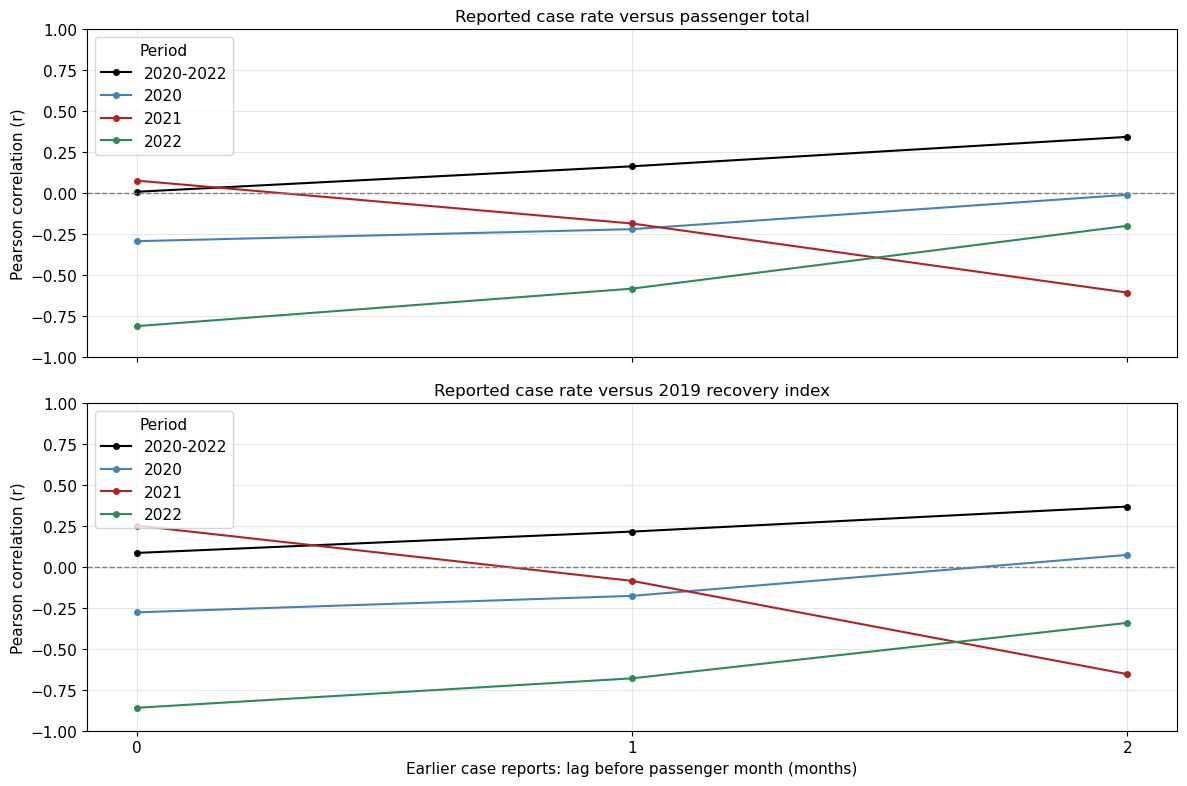

   Period  Lag_months             Outcome  N_months  Pearson_r  R_squared
2020-2022           0     Passenger total        36     0.0089     0.0001
2020-2022           0 2019 recovery index        36     0.0848     0.0072
2020-2022           1     Passenger total        35     0.1643     0.0270
2020-2022           1 2019 recovery index        35     0.2151     0.0462
2020-2022           2     Passenger total        34     0.3439     0.1183
2020-2022           2 2019 recovery index        34     0.3680     0.1354
     2020           0     Passenger total        12    -0.2926     0.0856
     2020           0 2019 recovery index        12    -0.2776     0.0771
     2020           1     Passenger total        11    -0.2193     0.0481
     2020           1 2019 recovery index        11    -0.1771     0.0314
     2020           2     Passenger total        10    -0.0095     0.0001
     2020           2 2019 recovery index        10     0.0731     0.0053
     2021           0     Passenger to

In [27]:
# Positive lag means earlier case reports are paired with later passenger data.
# Reindexing makes shift(1) exactly one calendar month, even if a month is absent.
monthly_comparison = pandemic.set_index("Datum").sort_index().asfreq("MS")
lag_rows = []
comparison_periods = [("2020-2022", monthly_comparison)]
comparison_periods += [(str(year), monthly_comparison.loc[str(year)].copy())
                       for year in [2020, 2021, 2022]]
for period, period_data in comparison_periods:
    for lag in [0, 1, 2]:
        shifted_cases = period_data["Covid_per_miljoen"].shift(lag)
        for outcome, column in [("Passenger total", "Totaal"), ("2019 recovery index", "Totaal_index")]:
            pairs = pd.DataFrame({"Cases": shifted_cases, "Passengers": period_data[column]}).dropna()
            slope, intercept, r, r2 = linear_summary(pairs["Cases"], pairs["Passengers"])
            lag_rows.append({"Period": period, "Lag_months": lag, "Outcome": outcome,
                             "N_months": len(pairs), "Pearson_r": r, "R_squared": r2})
lag_comparison = pd.DataFrame(lag_rows)
lag_comparison.to_csv(RESULT_DIR / "covid_recovery_lag_comparison.csv", index=False)
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, sharey=True)
period_colours = {"2020-2022": "black", "2020": "steelblue", "2021": "firebrick", "2022": "seagreen"}
for ax, outcome in zip(axes, ["Passenger total", "2019 recovery index"]):
    for period, colour in period_colours.items():
        subset = lag_comparison.loc[(lag_comparison["Period"] == period) &
                                     (lag_comparison["Outcome"] == outcome)]
        ax.plot(subset["Lag_months"], subset["Pearson_r"], label=period,
                color=colour, linewidth=1.5, marker="o", markersize=4)
    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_title(f"Reported case rate versus {outcome.lower()}")
    ax.set_ylabel("Pearson correlation (r)")
    ax.set_ylim(-1, 1); ax.legend(title="Period", loc="upper left"); ax.grid(alpha=0.3)
axes[-1].set_xlabel("Earlier case reports: lag before passenger month (months)")
axes[-1].set_xticks([0, 1, 2])
save_figure(fig, "covid_passenger_recovery_lags.png")
plt.show()
print(lag_comparison.round(4).to_string(index=False))


## 11. RQ3: Passenger-category recovery

Compare each category with its own same-month 2019 reference.


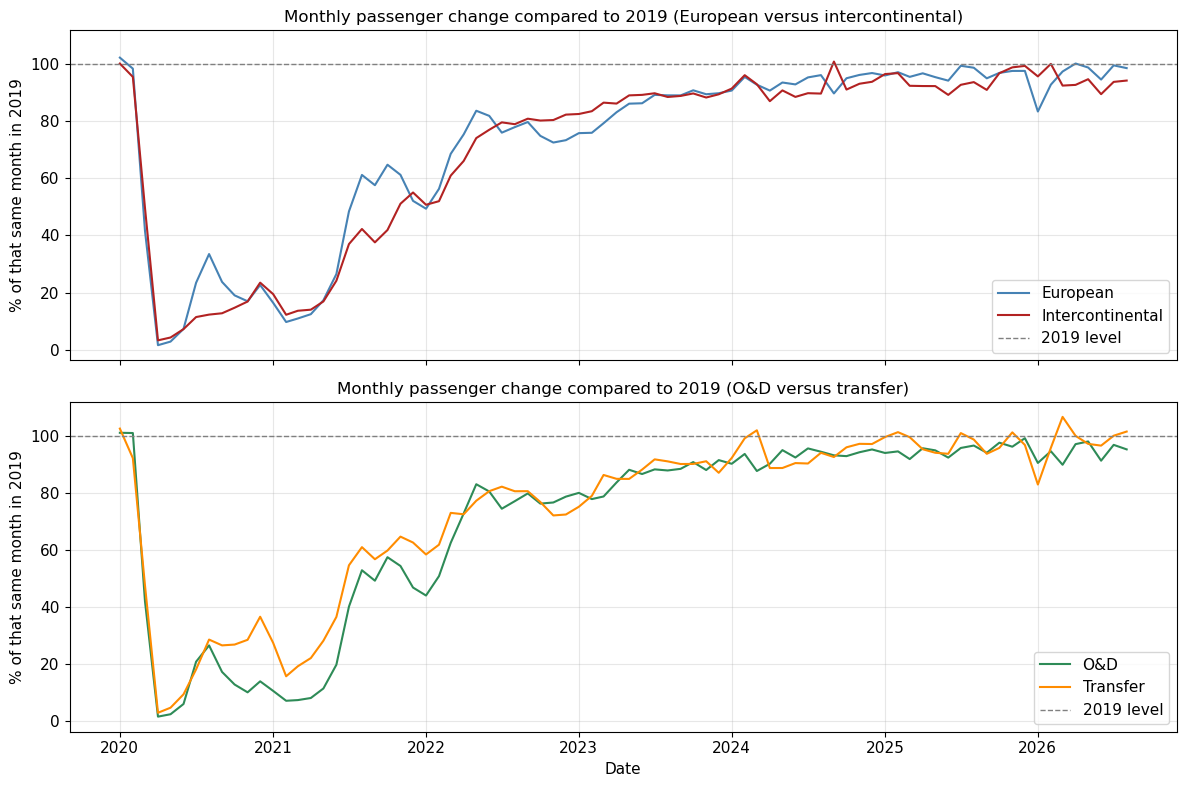

In [28]:
groups = passengers.loc[
    passengers["Jaar"] >= 2020
].copy()

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True, sharey=True
)

ax1.plot(
    groups["Datum"],
    groups["Europa_index"],
    label="European",
    color="steelblue",
    linewidth=1.5
)

ax1.plot(
    groups["Datum"],
    groups["Intercontinentaal_index"],
    label="Intercontinental",
    color="firebrick",
    linewidth=1.5
)

ax1.set_title("Monthly passenger change compared to 2019 (European versus intercontinental)")
ax1.set_ylabel("% of that same month in 2019")

ax2.plot(
    groups["Datum"],
    groups["OD_index"],
    label="O&D",
    color="seagreen",
    linewidth=1.5
)

ax2.plot(
    groups["Datum"],
    groups["Transfer_index"],
    label="Transfer",
    color="darkorange",
    linewidth=1.5
)

ax2.set_title("Monthly passenger change compared to 2019 (O&D versus transfer)")
ax2.set_xlabel("Date")
ax2.set_ylabel("% of that same month in 2019")

for ax in [ax1, ax2]:
    ax.axhline(
        100,
        color="gray",
        linestyle="--",
        linewidth=1,
        label="2019 level"
    )
    ax.legend()
    ax.grid(alpha=0.3)

fig.tight_layout()
Path("figure").mkdir(exist_ok=True)
save_figure(fig, "schiphol_passenger_groups.png")
plt.show()

## 12. RQ4: Disruption and recovery since 2020

Inspect the complete disruption and recovery period.


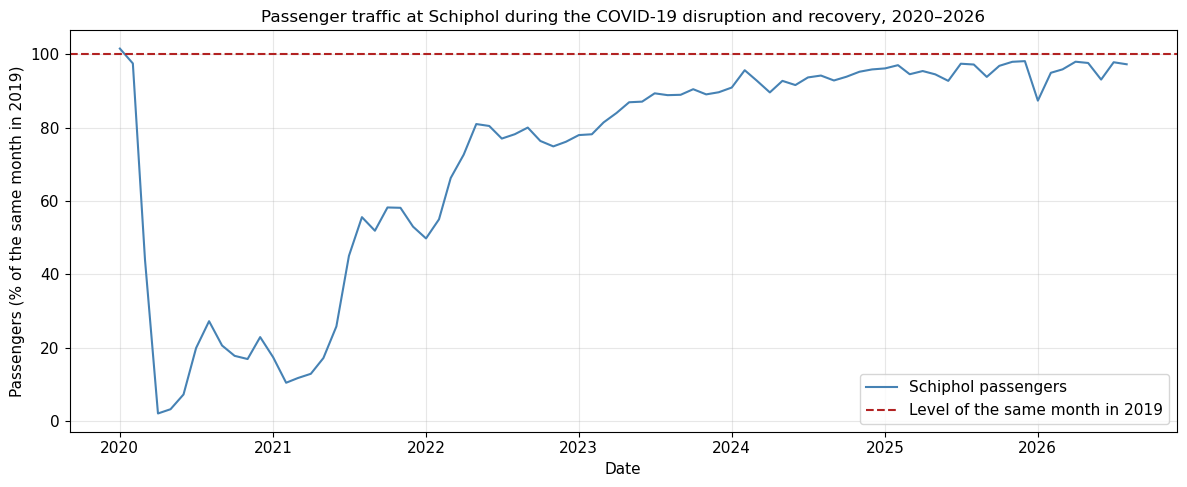

In [29]:
recovery_since_2020 = passengers.loc[
    passengers["Jaar"] >= 2020
].copy().sort_values("Datum")

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    recovery_since_2020["Datum"],
    recovery_since_2020["Totaal_index"],
    label="Schiphol passengers",
    color="steelblue",
    linewidth=1.5
)

ax.axhline(
    100,
    color="firebrick",
    linestyle="--",
    linewidth=1.5,
    label="Level of the same month in 2019"
)

ax.set_title("Passenger traffic at Schiphol during the COVID-19 disruption and recovery, 2020–2026")
ax.set_xlabel("Date")
ax.set_ylabel("Passengers (% of the same month in 2019)")
ax.legend()
ax.grid(alpha=0.3)

from pathlib import Path

Path("figure").mkdir(exist_ok=True)

fig.tight_layout()
save_figure(fig, "schiphol_disruption_and_recovery.png")
plt.show()

## 13. RQ4: Recovery from 2023 onwards

Inspect the most recent recovery period in more detail.


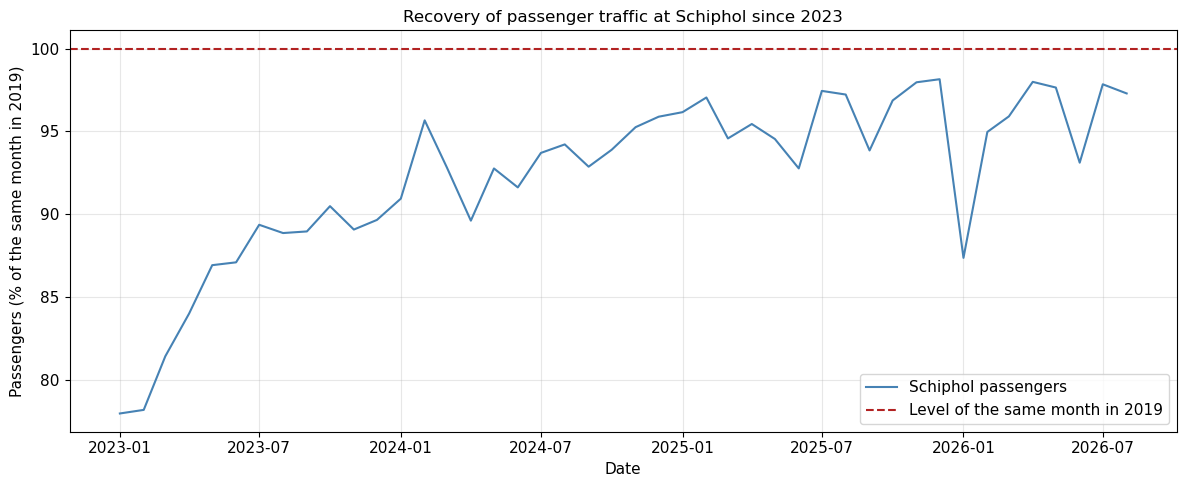

In [30]:
recent_recovery = passengers.loc[
    passengers["Jaar"] >= 2023
].copy()

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    recent_recovery["Datum"],
    recent_recovery["Totaal_index"],
    label="Schiphol passengers",
    color="steelblue",
    linewidth=1.5
)

ax.axhline(
    100,
    color="firebrick",
    linestyle="--",
    linewidth=1.5,
    label="Level of the same month in 2019"
)

ax.set_title("Recovery of passenger traffic at Schiphol since 2023")
ax.set_xlabel("Date")
ax.set_ylabel("Passengers (% of the same month in 2019)")
ax.legend()
ax.grid(alpha=0.3)

from pathlib import Path

Path("figure").mkdir(exist_ok=True)

fig.tight_layout()
save_figure(fig, "schiphol_recovery_since_2023.png")
plt.show()

## 14. RQ4: Prepare monthly comparison

Check complete years in the 2019-2025 raw-count comparison.


In [31]:
# select passengers from 2019 to 2025
# 2019 pre-covid, 2020-2022 pandemic, 2023-2025 recovery-period

years = list(range(2019,2026))

monthly_data = passengers.loc[
    passengers['Jaar'].isin(years),
    ['Jaar', 'Maandnummer', 'Totaal']
].copy()

monthly_data['Totaal'] = pd.to_numeric(
    monthly_data['Totaal'],
    errors='coerce'
)

monthly_data = monthly_data.sort_values(
    ['Jaar', 'Maandnummer']
)

# check if each year contains 12 months

for year in years:

    year_data = monthly_data.loc[
        monthly_data["Jaar"] == year
    ]

    number_of_months = year_data["Maandnummer"].nunique()
    missing_passengers = year_data["Totaal"].isna().sum()

    print(
        f"{year}: {number_of_months} months, "
        f"{missing_passengers} missing values"
    )

    if number_of_months != 12 or missing_passengers > 0:
        print(f"WARNING: Incomplete data for {year}")
    else:
        print(f"Data for {year} is complete.")

print("\nData completeness check finished.")


# passenger numbers in millions

monthly_data['Passengers_millions'] = (
    monthly_data['Totaal'] / 1_000_000
)


2019: 12 months, 0 missing values
Data for 2019 is complete.
2020: 12 months, 0 missing values
Data for 2020 is complete.
2021: 12 months, 0 missing values
Data for 2021 is complete.
2022: 12 months, 0 missing values
Data for 2022 is complete.
2023: 12 months, 0 missing values
Data for 2023 is complete.
2024: 12 months, 0 missing values
Data for 2024 is complete.
2025: 12 months, 0 missing values
Data for 2025 is complete.

Data completeness check finished.


## 15. RQ4: Monthly patterns by year

Visualise the return of the seasonal pattern without treating raw counts as seasonally adjusted.


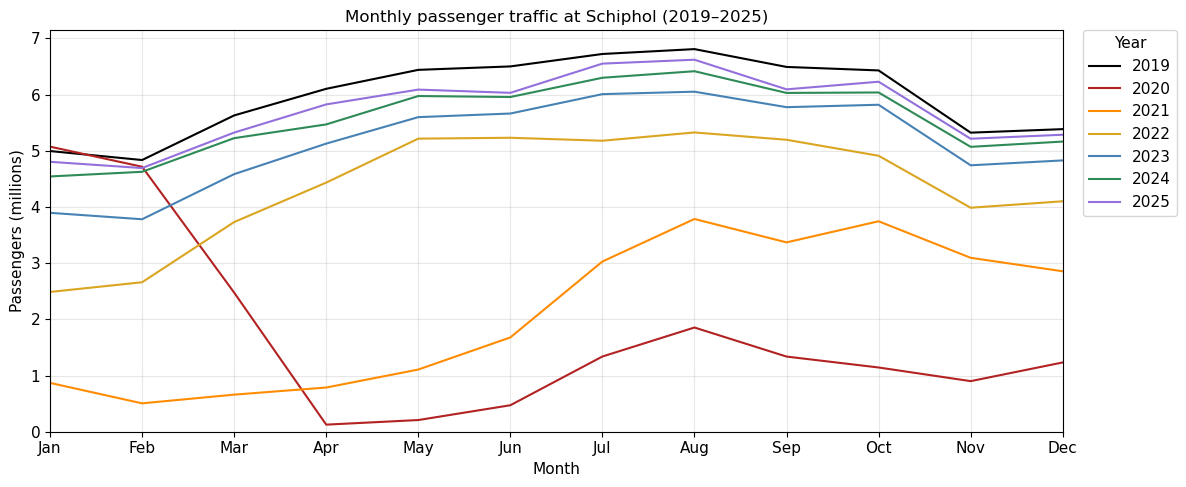

In [32]:
# Monthly comparison, using the same layout as the earlier figures.
colors = {
    2019: "black", 2020: "firebrick", 2021: "darkorange",
    2022: "goldenrod", 2023: "steelblue", 2024: "seagreen",
    2025: "mediumpurple"
}
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(12, 5))
for year in years:
    year_data = monthly_data.loc[
        monthly_data["Jaar"] == year
    ].sort_values("Maandnummer")
    ax.plot(
        year_data["Maandnummer"], year_data["Passengers_millions"],
        label=str(year), color=colors[year], linewidth=1.5
    )

ax.set_title("Monthly passenger traffic at Schiphol (2019–2025)")
ax.set_xlabel("Month")
ax.set_ylabel("Passengers (millions)")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(months)
ax.set_xlim(1, 12)
ax.set_ylim(bottom=0)
ax.legend(title="Year", loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
ax.grid(alpha=0.3)
Path("figure").mkdir(exist_ok=True)
fig.tight_layout()
save_figure(fig, "schiphol_monthly_comparison.png")
plt.show()


## 16. Recovery summary and reference-period sensitivity

Calculate category recovery dates and compare total-traffic reference periods.


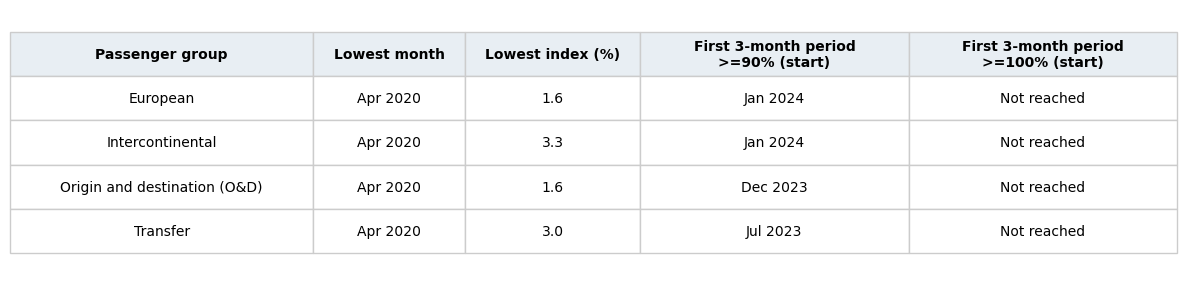

             Passenger group Lowest month  Lowest index (%) First 3-month period\n>=90% (start) First 3-month period\n>=100% (start)
                    European     Apr 2020               1.6                            Jan 2024                          Not reached
            Intercontinental     Apr 2020               3.3                            Jan 2024                          Not reached
Origin and destination (O&D)     Apr 2020               1.6                            Dec 2023                          Not reached
                    Transfer     Apr 2020               3.0                            Jul 2023                          Not reached


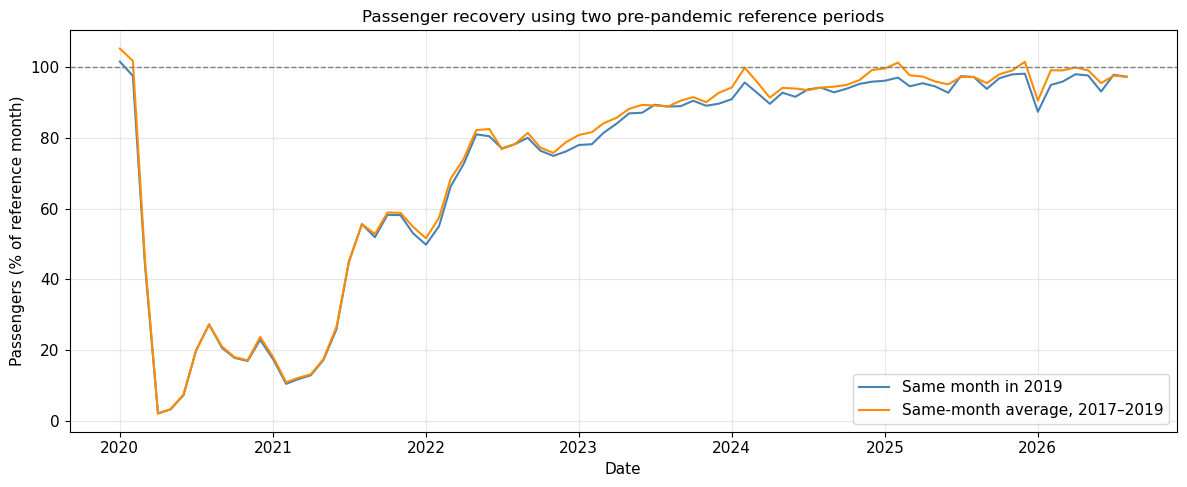

      Months  Index_2019  Index_2017_2019
Jaar                                     
2020      12       31.75            32.68
2021      12       34.79            35.33
2022      12       72.33            73.71
2023      12       86.01            87.72
2024      12       93.27            95.18
2025      12       96.01            97.96
2026       8       95.27            97.27


In [33]:
# Additional outputs used by the report: category recovery and baseline sensitivity.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

Path('figure').mkdir(exist_ok=True)
recovery = passengers.loc[passengers['Jaar'] >= 2020].sort_values('Datum').copy()
category_labels = {'Europa': 'European', 'Intercontinentaal': 'Intercontinental',
                   'OD': 'Origin and destination (O&D)', 'Transfer': 'Transfer'}
# Search from March 2020. Require three calendar-consecutive valid months;
# report the START of the qualifying interval, not its third month.
post_disruption = recovery.set_index('Datum').asfreq('MS').loc['2020-03-01':]
def first_sustained_start(series, threshold, months=3):
    """Return the first START of a run of qualifying calendar months."""
    if months < 1:
        raise ValueError("The recovery window must be at least one month.")
    series = series.asfreq("MS")
    meets = series.ge(threshold) & series.notna()
    qualifies = meets.copy()
    for offset in range(1, months):
        qualifies = qualifies & meets.shift(-offset, fill_value=False)
    return qualifies[qualifies].index[0].strftime("%b %Y") if qualifies.any() else "Not reached"

rows = []
for category, label in category_labels.items():
    series = post_disruption[f'{category}_index']
    low_date = series.idxmin()
    rows.append({'Passenger group': label, 'Lowest month': low_date.strftime('%b %Y'),
                 'Lowest index (%)': round(series.loc[low_date], 1),
                 'First 3-month period\n>=90% (start)': first_sustained_start(series, 90),
                 'First 3-month period\n>=100% (start)': first_sustained_start(series, 100)})
recovery_summary = pd.DataFrame(rows)
recovery_summary.to_csv('results/passenger_group_recovery_table.csv', index=False)
fig, ax = plt.subplots(figsize=(12, 3)); ax.axis('off')
table = ax.table(cellText=recovery_summary.values, colLabels=recovery_summary.columns,
                 loc='center', cellLoc='center', colWidths=[0.26, 0.13, 0.15, 0.23, 0.23])
table.auto_set_font_size(False); table.set_fontsize(10); table.scale(1, 2.3)
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('#cccccc')
    if row == 0:
        cell.set_facecolor('#e8eef3'); cell.set_text_props(weight='bold')
fig.tight_layout()
save_figure(fig, "passenger_group_recovery_table.png")
plt.show()
print(recovery_summary.to_string(index=False))

# Compare same-calendar-month baselines. Annual statistics below are unweighted
# means of monthly indices, NOT ratios of annual passenger totals.
baseline_3yr = passengers.loc[passengers['Jaar'].between(2017, 2019)].groupby('Maandnummer')['Totaal'].mean()
baseline_counts = passengers.loc[passengers['Jaar'].between(2017, 2019)].groupby('Maandnummer')['Totaal'].count()
if len(baseline_counts) != 12 or not baseline_counts.eq(3).all():
    raise ValueError('The 2017–2019 monthly baseline requires three valid observations per calendar month.')
recovery['Index_2017_2019'] = recovery['Totaal'] / recovery['Maandnummer'].map(baseline_3yr) * 100
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(recovery['Datum'], recovery['Totaal_index'], label='Same month in 2019', color='steelblue', linewidth=1.5)
ax.plot(recovery['Datum'], recovery['Index_2017_2019'], label='Same-month average, 2017–2019', color='darkorange', linewidth=1.5)
ax.axhline(100, color='gray', linestyle='--', linewidth=1)
ax.set(title='Passenger recovery using two pre-pandemic reference periods',
       xlabel='Date', ylabel='Passengers (% of reference month)')
ax.legend(); ax.grid(alpha=0.3); fig.tight_layout()
save_figure(fig, "Recovery_comparison_2019_vs_2017_2019.png")
plt.show()
baseline_summary = recovery.groupby('Jaar').agg(Months=('Datum','size'), Index_2019=('Totaal_index','mean'), Index_2017_2019=('Index_2017_2019','mean'))
baseline_summary.to_csv('results/recovery_baseline_summary.csv')
print(baseline_summary.round(2).to_string())


## 17. Recovery-window sensitivity

Compare 90% and 100% thresholds over three and six consecutive calendar months. Report the start of each qualifying run.


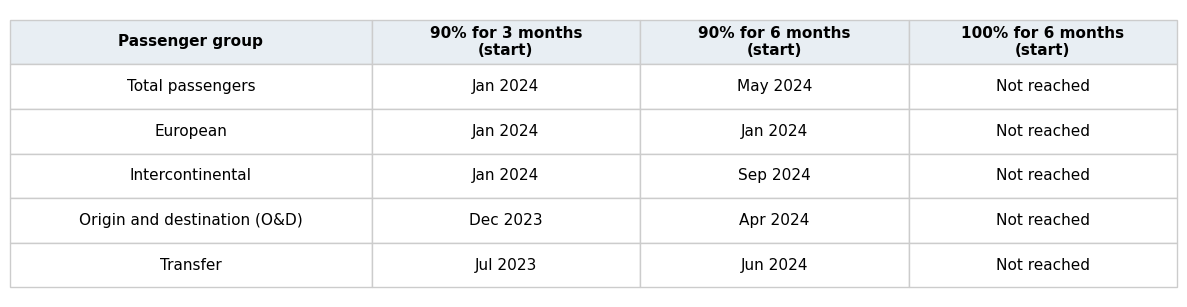

             Passenger_group  Threshold_percent  Consecutive_months First_period_start
            Total passengers                 90                   3           Jan 2024
            Total passengers                 90                   6           May 2024
            Total passengers                100                   3        Not reached
            Total passengers                100                   6        Not reached
                    European                 90                   3           Jan 2024
                    European                 90                   6           Jan 2024
                    European                100                   3        Not reached
                    European                100                   6        Not reached
            Intercontinental                 90                   3           Jan 2024
            Intercontinental                 90                   6           Sep 2024
            Intercontinental               

In [34]:
# Compare a short and longer recovery window without changing the reference data.
threshold_rows = []
threshold_groups = {"Totaal": "Total passengers", **category_labels}
for category, label in threshold_groups.items():
    series = post_disruption[f"{category}_index"]
    for threshold in [90, 100]:
        for months in [3, 6]:
            start = first_sustained_start(series, threshold, months)
            threshold_rows.append({"Passenger_group": label, "Threshold_percent": threshold,
                                   "Consecutive_months": months, "First_period_start": start})
threshold_sensitivity = pd.DataFrame(threshold_rows)
threshold_sensitivity.to_csv(RESULT_DIR / "recovery_threshold_sensitivity.csv", index=False)
threshold_table_rows = []
for category, label in threshold_groups.items():
    series = post_disruption[f"{category}_index"]
    threshold_table_rows.append({"Passenger group": label,
        "90% for 3 months\n(start)": first_sustained_start(series, 90, 3),
        "90% for 6 months\n(start)": first_sustained_start(series, 90, 6),
        "100% for 6 months\n(start)": first_sustained_start(series, 100, 6)})
threshold_table = pd.DataFrame(threshold_table_rows)
fig, ax = plt.subplots(figsize=(12, 3.2)); ax.axis("off")
table = ax.table(cellText=threshold_table.values, colLabels=threshold_table.columns,
                 loc="center", cellLoc="center", colWidths=[0.31, 0.23, 0.23, 0.23])
table.auto_set_font_size(False); table.set_fontsize(11); table.scale(1, 2.3)
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("#cccccc")
    if row == 0:
        cell.set_facecolor("#e8eef3"); cell.set_text_props(weight="bold")
save_figure(fig, "passenger_recovery_threshold_sensitivity.png")
plt.show()
print(threshold_sensitivity.to_string(index=False))
